#FarEvader

##The Introduction

The Berlin Transit System (BVB) operates via an Honor System: purchase a ticket or pass, validate it, and ride free; or don't, and ride free, with the risk of being inspected by the BVB police, fined and/or arrested. In this assignment, with basic Machine Learning techniques and simple regression models, I aim to dishonor this system.

My ML pipeline, FarEvader, uses publically-sourced police inspection data to predict the risk of a police inspection being reported at a specific station, on a specific line, on a specific day of the week, at a specific time of the day. First, I compiled and processed the data to funnel it through two separate regression models (Linear and Poisson) to compare their respective performance. Then, I adjusted certain features and parameters of the models (day of week, length of time interval, etc) to observe their effect on the prediction error value and optimize the models performance. Lastly, I tested the performance of these models under these conditions and visualized their performance to determine with a certain amount of certainty which model is the best at predicting the risk of inspection.

*Note: with this pipeline and given the data I have access to, I am unable to predict the risk of a police inspection occuring in the BVB; what I can do and what I attempted to do below, is predict the probability of a police inspection at a specific time on a specific day on a specific line in a specific station being *reported* to the public-sourced I retrieved my data from. This can be used as a proxy to determine the risk of a police inspection, but should not be used as a substitute for a ticket, or believed to be more than it is - a prediction.

In [171]:
#importing the data and the libraries

import numpy as py
import seaborn as sea
import pandas as panda
from math import e, inf
from random import choice as rando
import matplotlib.pyplot as libby
from sklearn.linear_model import PoissonRegressor, LinearRegression

train = panda.read_csv('C:/Users/Hayoo/Downloads/CS156/Portfolio/1/data/training-data.csv') #training data
valid = panda.read_csv('C:/Users/Hayoo/Downloads/CS156/Portfolio/1/data/validation-data.csv') #validation data
test = panda.read_csv('C:/Users/Hayoo/Downloads/CS156/Portfolio/1/data/test-data.csv') #test data

##The Data

Upon our arrival in Berlin, an alumni (who will remain anonymous; I would tempt the German legal system, they should not) introduced us to a Telegram groupchat (whose name will also remain undisclosed) where the people of Berlin, ~40,000 of them, report a police inspection incident when it occurs by stating the name of the station and the code of the line, often but optionally along with other information (the appearance of the inspector, the number of them, etc), like so:

'3 Menschen steigen jetzt in den m27 Richtung s jungfernheide17:31', the most recent report in the groupchat.

I collected this data by downloading the Telegram groupchat message history, dating from March, 2022 to about three weeks ago when I downloaded it. It came in the form of 44 HTML files of ~10,000 messages each, totalling at around 400,000 messages across all HTMLs. I used the website in Appendix A to merge the HTMLs, but because of the density of the files and the sheer quantity of them, the website kept crashing on me - my solution was to split them into 3 files of 22 HTMLs, 11 HTMLs and 11 HTMLs for training, validation and testing respectively.

From there, I uploaded the training file into ChatGPT and used an elaborate prompt to convert the HTML into a useable database consisting of 5 columns: id (e.g. M01234), line (e.g. U8), station (e.g. Hermannplatz, which is where we live!), day (e.g. U for Sunday), time (e.g 1534 meaning 3:34pm). After much prompting and reprompting, the full chat of which is in Appendix B, ChatGPT was able to provide a full and accurate table for each data set, found in the data folder of this repo.

In [172]:
#processing the data 

##training data 
train['time'] = panda.to_datetime(train['time'], format='%H:%M').dt.floor('15min').dt.strftime('%H:%M') #grouping the time into 15 minute intervals
train = train.groupby(['line','station', 'day', 'time']).size().reset_index(name='inspections') #counting inspections for each line-station-day-time combination

##validation data
valid['time'] = panda.to_datetime(valid['time'], format='%H:%M').dt.floor('15min').dt.strftime('%H:%M')
valid = valid.groupby(['line','station', 'day', 'time']).size().reset_index(name='inspections')


This block of code is simply to format the data into ingestible forms, so I'm not quite sure if it is part of processing or pre-processing. Nonetheless, what it's doing is simply taking the data from the folder (training and validation separately) and formats the times into 15 minute intervals so that the data points aren't too sparse, using the .dt.floor() function, which is something new I learned!. Then, it groups the formatted data into line-station-day-time combinations and counts how many unique incidents have been reported in this combination of conditions. 

This grouping is specifically done to evaluate the risk metric of a new report according to it's location on the scale between most risky combination, and least risky combinations. Why this specific combination is justified through performance evaluations much below, as well as through visualizations right below.

Training data summary:
       inspections
count  5621.000000
mean      1.092510
std       0.344219
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max       5.000000
Top 5 incidents with the most inspections:
     line            station day   time  inspections
4014   U8     Alexanderplatz   M  12:15            5
4840   U8  Rosenthaler Platz   W  14:00            5
4993   U8  Weinmeisterstraße   F  13:30            5
3978   U8     Alexanderplatz   F  09:00            4
4003   U8     Alexanderplatz   M  08:15            4
Top 5 incidents with the fewest inspections:
  line                         station day   time  inspections
0   M1                 Am Kupfergraben   T  14:00            1
1   M1               Bornholmer Straße   W  17:30            1
2   M1              Eberswalder Straße   F  16:15            1
3   M1              Eberswalder Straße   Z  15:15            1
4   M1  Eberswalder Straße/Pappelallee   F  13:30            1


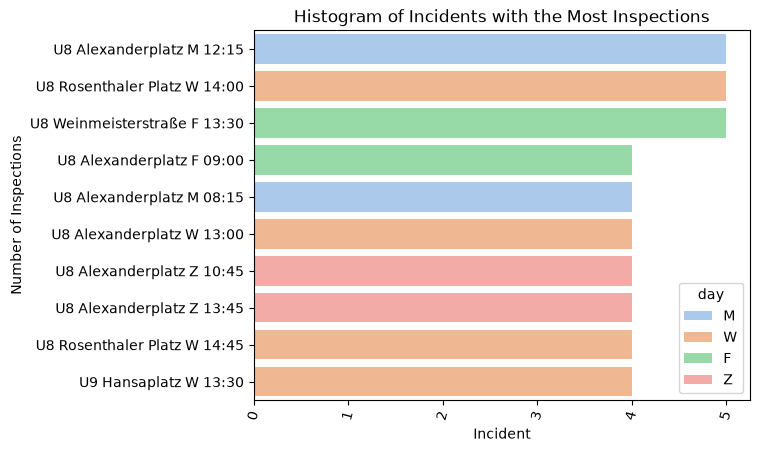

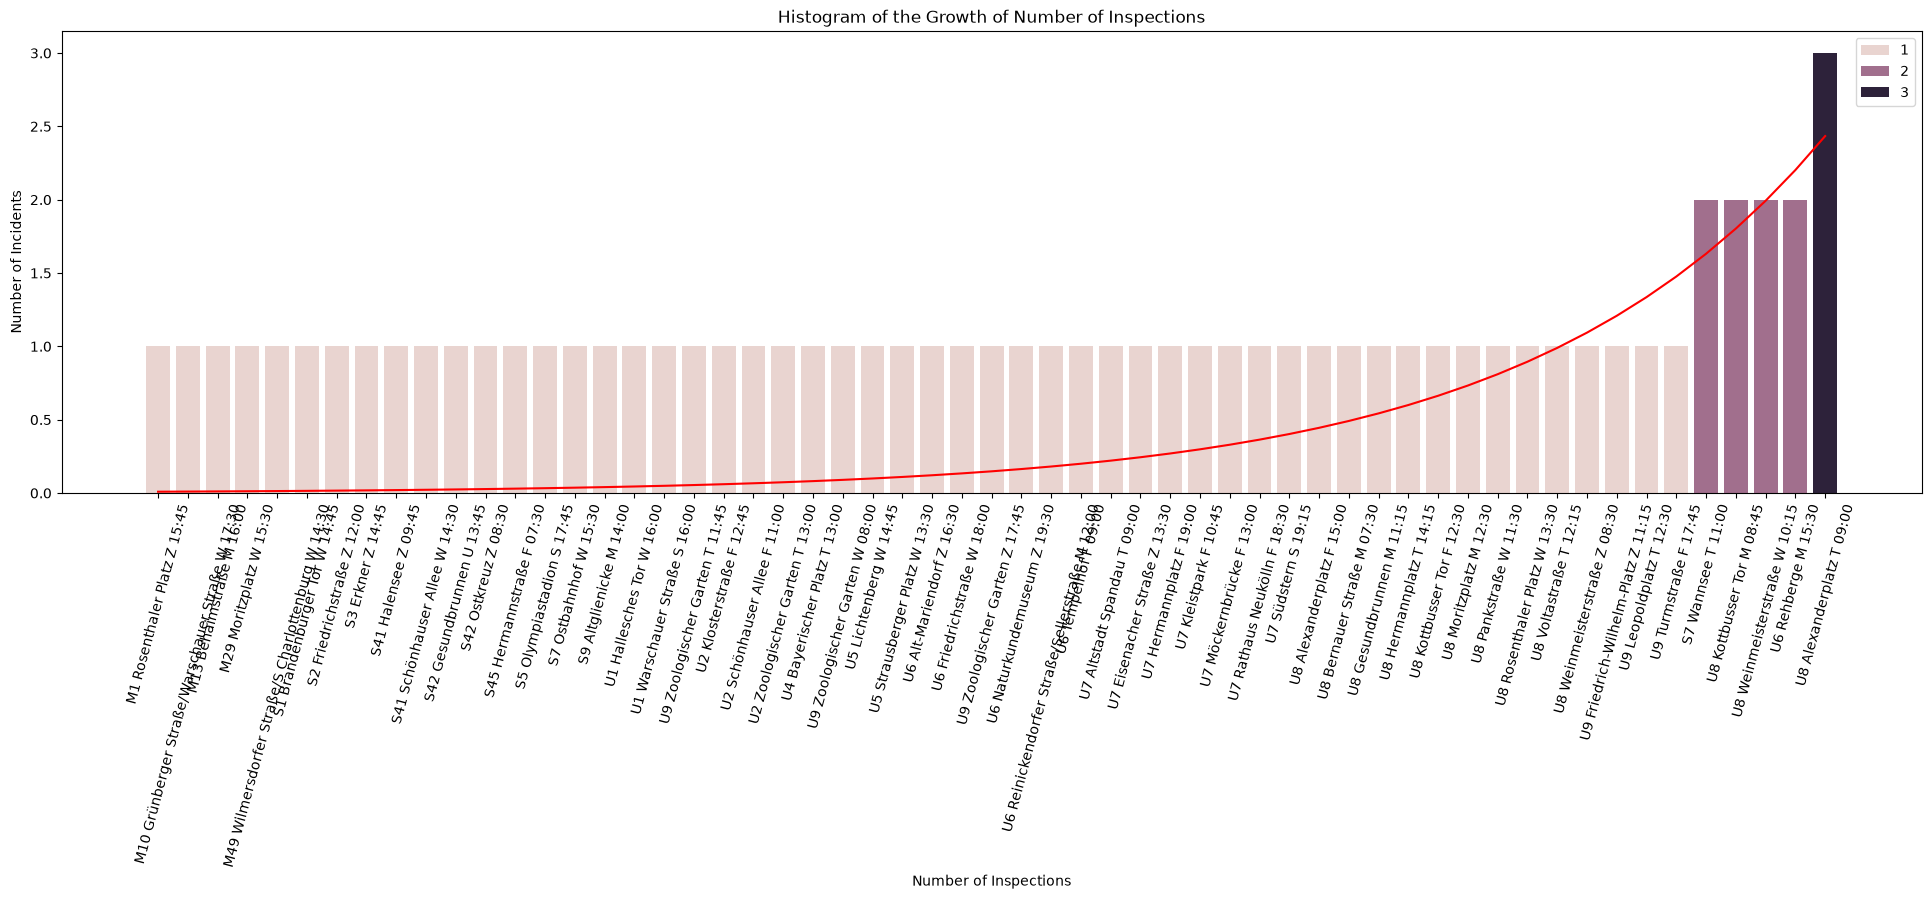

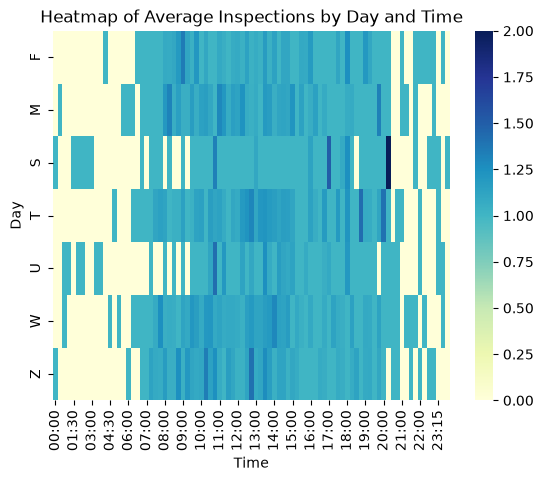

In [173]:
#visualizing the training data

##basic statistics of the training data
print('Training data summary:')
print(train.describe())

print('Top 5 incidents with the most inspections:')
print(train.nlargest(5, 'inspections'))

print('Top 5 incidents with the fewest inspections:')
print(train.nsmallest(5, 'inspections'))

##labelling each incident by line, station, day, and time, for better visualization

train['incident'] = (train['line'] + ' ' +
                    train['station'] + ' ' + 
                    train['day'] + ' ' +
                    train['time'].astype(str))

##histogram of the 50 incidents with the most inspections

top = train.nlargest(10, 'inspections')
sea.barplot(data=top, y='incident', x='inspections', hue='day', palette = 'pastel')
libby.xlabel('Incident')
libby.ylabel('Number of Inspections')
libby.title('Histogram of Incidents with the Most Inspections')

libby.xticks(rotation=75)
libby.show()

##histogram of the growth of number of inspections
libby.figure(figsize=(24, 6))

growth_values = train.sort_values(by='inspections', ascending=True)
growth_x = []
growth_y = []

for i in range(0, len(growth_values)-1, 100):
    growth_x.append(growth_values.iloc[i]['incident'])
    growth_y.append(growth_values.iloc[i]['inspections'])

sea.barplot(x = growth_x, y = growth_y, hue = growth_y)
libby.xlabel('Number of Inspections')
libby.ylabel('Number of Incidents')
libby.title('Histogram of the Growth of Number of Inspections')

x = py.arange(len(growth_y))
libby.plot(x, 0.009 * py.exp(0.1 * x), color='red')
libby.xticks(rotation=75)
libby.show()

##heatmap of day and time of inspections (AI Generated Code)
heatmap_data = train.pivot_table(
    index='day',
    columns='time',
    values='inspections',
    aggfunc='mean',
    fill_value=0
)
sea.heatmap(heatmap_data, cmap='YlGnBu', annot=False, fmt=".1f")
libby.title('Heatmap of Average Inspections by Day and Time')
libby.xlabel('Time')
libby.ylabel('Day')
libby.show()



##The Visualizations

I have generated three separate visualizations to demonstrate distinct patterns in the data that the pipeline should pick up on to predict future data.

The first visualization just shows us that the data pre-processing worked. It demonstrates that the number of inspections are not uniform, that some stations recieve noticebly more traction from both the people and the police (Alexanderplatz, center of the touristy area). It also indicates to us that the number of reports is non-insignificant, as in, if the highest was 2, it would be hard to differentiate between a riskier area and a less risky area of say 1 report. This means that the data is sufficient for this purpose.

The second visualization captures the exponential growth of the data, which helps with the algorithm predicting intermediate values. I expected the data to follow an exponential curve and planned to implement it into my algorithm, but firt I had to prove it. So, I sorted the values in ascending order and plotted the number of inspections at 1 entry in each 100. The curve fit to this barplot is via the equation:

\[
y = 0.009e^{0.1x}
\]

Which will prove helpful later for fitting the exponential curve to the Squishification function that maps inpection count to risk probability.

The third visualization serves an essential purpose: at this point we know the inspections aren't uniform to line-station-day-time combinations, and from experience we can infer that it is station-dependent (Alexanderplatz recieves more traction than say Frankfuter Tor consistently on any day at any time). This plot is a heat-map of time-day report count, that shows us with great confidence that the inspections are heavily time-dependent; the inspections could happen uniformly at all times of day, or even randomly and thus unpredictably throughout the days, but this figure proves that they don't - significantly more inspections happen during the day rather than at night. 

Lastly, something we can infer, albeit with less confidence, is that the day of week plays a factor in the inspection count. While all the days feature a distinct blue blob of inspections in their middle, the outliers or splatters to this blob differ slightly day to day. This distinction should help to predict with more accuracy, but it's actual value will be determined more securely later on.


In [174]:
#fitting the data to a Linear and Poisson Regressor model

X = panda.get_dummies(train[['line','station', 'day','time']]) ##turn the categorical variable into numerical values using one-hot encoding
y = train['inspections']


##linear regression model
linear_model = LinearRegression()
linear_model.fit(X, y)

##poisson regression model
poisson_model = PoissonRegressor()
poisson_model.fit(X, y)

,"alpha alpha: float, default=1Constant that multiplies the L2 penalty term and determines theregularization strength. ``alpha = 0`` is equivalent to unpenalizedGLMs. In this case, the design matrix `X` must have full column rank(no collinearities).Values of `alpha` must be in the range `[0.0, inf)`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the linear predictor (`X @ coef + intercept`).",True
,"solver solver: {'lbfgs', 'newton-cholesky'}, default='lbfgs'Algorithm to use in the optimization problem:'lbfgs' Calls scipy's L-BFGS-B optimizer.'newton-cholesky' Uses Newton-Raphson steps (in arbitrary precision arithmetic equivalent to iterated reweighted least squares) with an inner Cholesky based solver. This solver is a good choice for `n_samples` >> `n_features`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features` because it explicitly computes the Hessian matrix. .. versionadded:: 1.2",'lbfgs'
,"max_iter max_iter: int, default=100The maximal number of iterations for the solver.Values must be in the range `[1, inf)`.",100
,"tol tol: float, default=1e-4Stopping criterion. For the lbfgs solver,the iteration will stop when ``max{|g_j|, j = 1, ..., d} <= tol``where ``g_j`` is the j-th component of the gradient (derivative) ofthe objective function.Values must be in the range `(0.0, inf)`.",0.0001
,"warm_start warm_start: bool, default=FalseIf set to ``True``, reuse the solution of the previous call to ``fit``as initialization for ``coef_`` and ``intercept_`` .",False
,"verbose verbose: int, default=0For the lbfgs solver set verbose to any positive number for verbosity.Values must be in the range `[0, inf)`.",0
Name,Type,Value
"coef_ coef_: array of shape (n_features,)Estimated coefficients for the linear predictor (`X @ coef_ +intercept_`) in the GLM.","ndarray[float64](552,)","[-0.,-0.,-0.,...,-0.,-0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](552,)","['line_M1','line_M10','line_M11',...,'time_23:15','time_23:30', 'time_23:45']"
intercept_ intercept_: floatIntercept (a.k.a. bias) added to linear predictor.,float64,0.08213


#The Models

To achieve the pipeline that predicts inspections the most accurately, I couldn't decide between using a simple Linear Regressor, or a more complex Poisson Regressor to predict the inspection counts in a specific line-station-day-time. So here, I decided to implement both, measure their performances and cross-compare their prediction errors to determine for certain which model predicts the most accurately.

##Linear Regression
Using Sci-Kit Learn's Linear Regression package, I fit the X values (the training data's line-station-day-time columns) to the y values (the inpection count for each combination). The .get_dummies() function here I learned uses one-hot encoding to transform the categorical variables ('U8', 'Alexanderplatz', etc) to values the package can ingest (True/False, 0/1) and from there fit the line of best fit. It does so by adjusting the features following this equation:

\[
\hat{y} = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p
\]

Where y_hat is the predicted number of inspections, beta_0 is the line's intercept, beta_1, beta_2, ldots and beta_p are the learned coefficients. The model adjusts these coefficients interatively to reduce the sum of squared-error (SSE) and thus optimize the regressor.

##Poisson Regression
Sci-Kit Learn has another package (God bless), the Poisson Regressor package, that fits a Poisson distribution to the data in order to predict the count of an event occuring - in this case, being inspected in the line-station-time-day. It uses the Poisson equation to fit this distribution:

[
\hat{y} = e^{\beta_0 + \beta_1x_1 + \cdots + \beta_px_p}
]

Where (\hat{y}) is the predicted number of inspections, (e) is Euler's number, and the (\beta) coefficients are learned from the training data. Unlike Linear Regression, the exponential function ensures that predictions are non-negative, which makes it more suitable for count data. The model learns these coefficients by minimizing the Poisson deviance, measuring how far its predictions are from the actual inspection counts.

The blocks below model the data to these two regression algorithms, predict the risk probabilities under each model, compare it to the validation data and measure each's performance, as you will observe soon.


In [175]:
#defining the function to predict the number of inspections and convert that number into a risk probability

def squishification(value, min, max, exp = 1):
    '''
    inputs: value (float), min (float), max (float)
    output: risk (float) between 0.05 and 0.95

    This function takes the predicted number of inspections and,
    depending on the model (linear or poisson) or data (actual or predicted)
    it squishes it from the bounds it was generated in to the bounds of 0.05 and 0.95.
    It is done exponentially, raised to the power of [exp], because the inspection number grows exponentially,
    as observed in the figure above. 
    The exponent is variable because I want to adjust it down the line to find the best fit for the data.
    '''
    if value < min:
        return 0
    elif value > max:
        return 1
    else:
        return 0.05 + ((e**(exp*(value - min)/(max - min)) - 1)/ (e - 1))*0.9

def predict(line, station, day, time, model = linear_model, squishify = True):
    '''
    inputs: line (str), station (str), day (str), time (str), model (linear of poisson) 
    output: prediction (float) of the selected model

    This function takes the line, station, day and time of an incident and uses the selected model
    to predict the number of inspections for that incident. Then, calling on the squishification function,
    it converts this number into a risk of inspection between 0.05 and 0.95, where the former is the minimum risk
    and the latter is the maximum risk.
    '''

    incident = panda.DataFrame([{"line": line, "station": station, "day": day, "time": time}])

    if line + ' ' + station + ' ' + day + ' ' + str(time) not in train['incident'].values: #if the incident is not in the training data, it returns 0
        return squishification(0, linear_min, linear_max)
    
    prediction = model.predict(panda.get_dummies(incident).reindex(columns=X.columns, fill_value=0)) #predicts the number of inspections as per the selected model

    if model == linear_model:
        return squishification(prediction[0], linear_min, linear_max) #bounds of the linear model's prediction for min and max
    return squishification(prediction[0], poisson_min, poisson_max) #bounds of the poisson model's prediction for min and max

##tracking the minimum and maximum predictions for both models to use in the squishification function
linear_predictions = linear_model.predict(X)
poisson_predictions = poisson_model.predict(X)

linear_min = linear_predictions.min()
linear_max = linear_predictions.max()

poisson_min = poisson_predictions.min()
poisson_max = poisson_predictions.max()

train_min = train['inspections'].min()
train_max = train['inspections'].max()

print('The Linear Model Minimum:', linear_min, 'and the Linear Model Maximum:', linear_max)
print('The Poisson Model Minimum:', poisson_min, 'and the Poisson Model Maximum:', poisson_max)
print('The Training Data Minimum:', train_min, 'and the Training Data Maximum:', train_max)


The Linear Model Minimum: 0.7783889226025119 and the Linear Model Maximum: 1.6523061688725305
The Poisson Model Minimum: 1.0766274450846824 and the Poisson Model Maximum: 1.1330181596545037
The Training Data Minimum: 1 and the Training Data Maximum: 5


#The Functions

I programmed a few functions (squishification and predict) to help with predict the inspection count for each incident and from there tranform that count into a risk probability for each incident. They do so like so:

##Predict Function

I made this function instead of using Sci-Kit Learn's built-in one because there are some line-station-day-time combinations that exist in the validation but not in the training data, and vice versa. For these incidents, the algorithm would return an error if asked to predict a value for it, because it doesn't exist in the model. So, instead of filling in the value of 0 for each line-station-day-time combination that failed to show up in the training data (which I did, and it took 2GBs of data just to process), I decided that if the combination didn't exist in the data, the custom-built predict function would just return 0.

Furthermore, if the value does exist in both validation and training datasets (which I sure hope it does), it returns the model's built-in function's value for the incident. However, it does so not before transforming this inspection count into a risk probability using the respective squishify function.

##Squishification Function

This function, not entirely unlike the Neural Network's squishification function, transforms the predicted count (if from linear, in between 0 and 2, and if poisson between 0 and 7) into a probability between 0.05 and 0.95. Why this range specifically, instead of the traditional 0 to 1, is that an inspection is not guaranteed, even at the height of rush hour in the busiest station, and neither is a risk ever impossible, even in a desolate area; I do not want to give off the impression, nor generate the prediction, that either is possible, thus the shrunk bounds.

Otherwise, the function matches the values in between 0.05 and 0.95 not linearly, rather in an exponential fashion, because of the exponential growth exhibited by the data as seen in the third visualization above. I will test, down the line, whether linear would be a better fit for the data, and have thus left the power of the exponent variable (e = 1 makes the equation linear).

A combination of these two functions uses the model and the data and transforms a line-station-day-time incident query into a inspection risk probability.

In [176]:
#measuring the performance of the models

def error(data = valid, model = linear_model):
    err = 0

    for incident in data.values:
        prediction = predict(incident[0], incident[1], incident[2], incident[3], model)
        actual = squishification(incident[4], train_min, train_max)

        err += abs(prediction - actual)

    return err/len(data)

print('The Linear Model error value:', error(model = linear_model)) #linear model error
print('The Poisson Model error value:', error(model = poisson_model)) #poisson model error

The Linear Model error value: 0.09363401131067849
The Poisson Model error value: 0.09330481700864218


##The Performance

The Error function implemented above iterates through every entry in the validation data and takes it's line-station-day-time combination to predict the risk value for that incident. It then compares it to the actual risk value (it's squishified inspection count) and computes it's absolute error. Lastly, it averages it over the length of the validation data, and returns the error value for the validation data under the selected model.

The error for the Linear model is 0.0936 or 9.36%, and the error for the Poisson model is , which I would say is pretty darn good for a first-try in and ML pipeline.


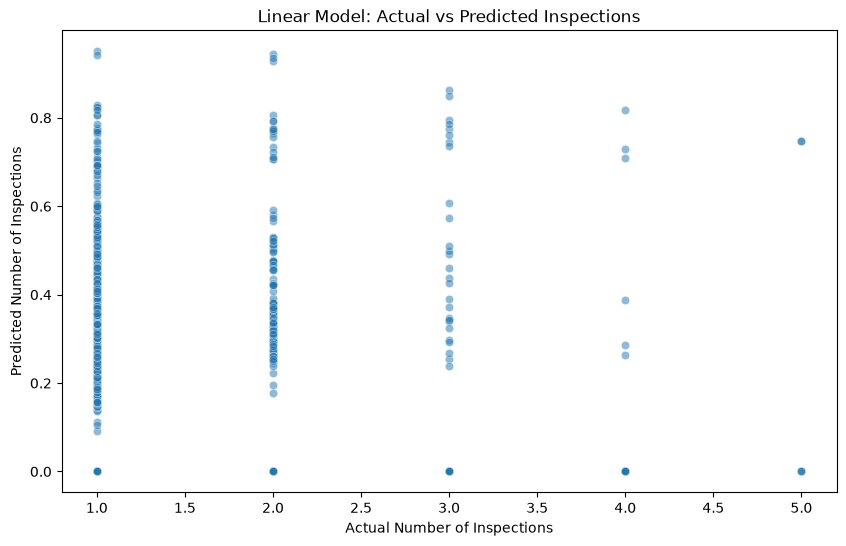

In [177]:
##Visualizing the performance of the models


##visualizing the performance of the linear model

linear_predictions = []
actual_values = []

for incident in valid.values:
    linear_predictions.append(predict(incident[0], incident[1], incident[2], incident[3], model = linear_model, squishify = False))
    actual_values.append(incident[4])

libby.figure(figsize=(10, 6))
sea.scatterplot(x = actual_values, y = linear_predictions, alpha = 0.5)

libby.xlabel('Actual Number of Inspections')
libby.ylabel('Predicted Number of Inspections')
libby.title('Linear Model: Actual vs Predicted Inspections')

libby.show()


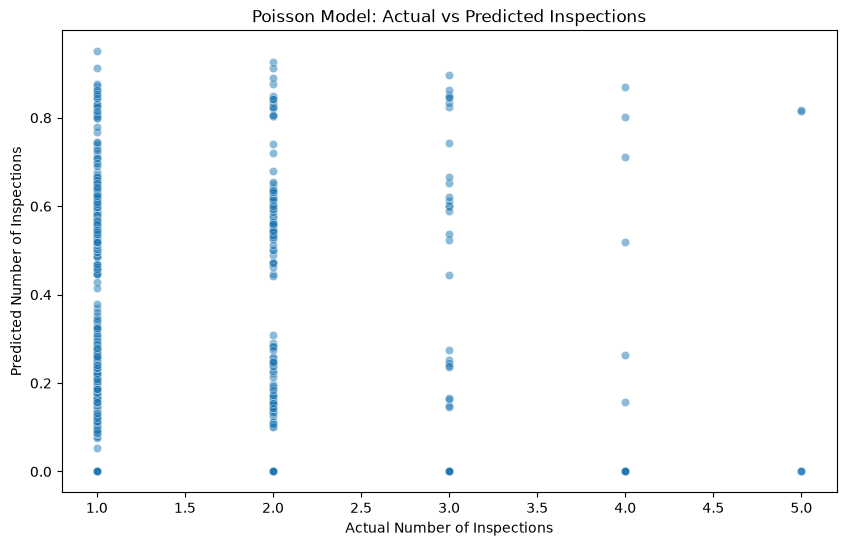

In [178]:
##visualizing the performance of the poisson model

poisson_predictions = []

for incident in valid.values:
    poisson_predictions.append(predict(incident[0], incident[1], incident[2], incident[3], model = poisson_model, squishify = False))

libby.figure(figsize=(10, 6))
sea.scatterplot(x = actual_values, y = poisson_predictions, alpha = 0.5)

libby.xlabel('Actual Number of Inspections')
libby.ylabel('Predicted Number of Inspections')
libby.title('Poisson Model: Actual vs Predicted Inspections')

libby.show()

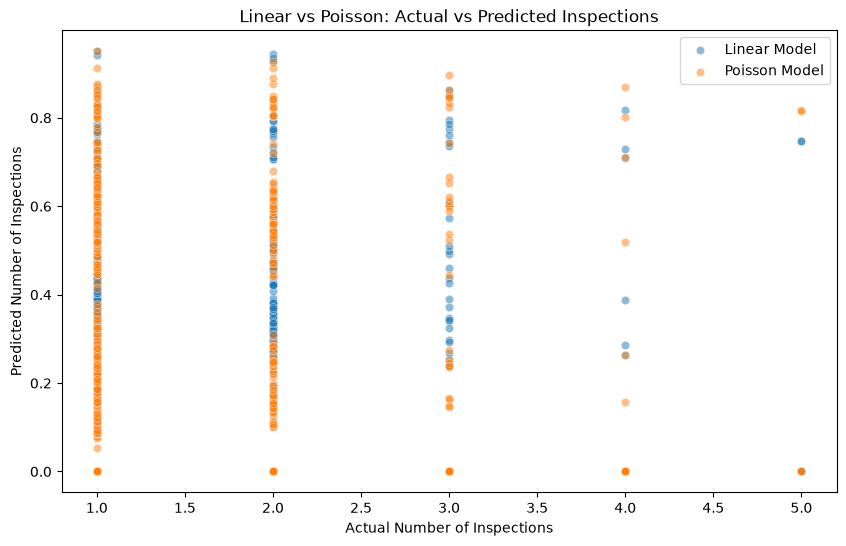

The Linear Model error value: 0.09484559039824883
The Poisson Model error value: 0.09460859183280013


In [179]:
##visualizing the performance of both models (AI generated code)

libby.figure(figsize=(10, 6))

sea.scatterplot(x = actual_values, y = linear_predictions, alpha = 0.5, label = 'Linear Model')
sea.scatterplot(x = actual_values, y = poisson_predictions, alpha = 0.5, label = 'Poisson Model')

libby.xlabel('Actual Number of Inspections')
libby.ylabel('Predicted Number of Inspections')
libby.title('Linear vs Poisson: Actual vs Predicted Inspections')

libby.legend()
libby.show()

##testing both models on the test data


###test data
test['time'] = panda.to_datetime(test['time'], format='%H:%M').dt.floor('15min').dt.strftime('%H:%M')
test = test.groupby(['line','station', 'day', 'time']).size().reset_index(name='inspections')

print('The Linear Model error value:', error(data = test, model = linear_model)) #linear model error
print('The Poisson Model error value:', error(data = test, model = poisson_model)) #poisson model error

##Conclusion
As you can see above, both models work quite well to predict whether an inspection will happen at a given time, on a given day, on a given line in a given station within the BVB Transit System, with an average accuracy of 91.6% accross both models with the validation data. The Linear Regression model seems to work slightly better than the Poisson Regression Model, as verified by the test data above (9.4% error).

That is all for now... Happy Fare Evading y'all!


In [180]:
##you can use this line to predict the risk of inspection for a specific incident using your desired model, to satify all your Fare-Evasion needs!

float(predict('U8','Alexanderplatz','M','08:00', model = linear_model)) 

0.74082073593118

#Appendix

##Appendix A

[HTML Merge Website](https://www.merge-json-files.com/html-merger)

##Appendix B

[General Assignment Chat:](https://chatgpt.com/share/6ad54696-cf98-83e9-b08b-f4db2e76cfa7)

[Pre-processing Data Chat #1](https://chatgpt.com/share/6ad54750-fd14-83eb-97fe-10a03fdd2d82)
[Pre-processing Data Chat #2](https://chatgpt.com/share/6ad546fe-60a8-83ed-8b4a-e3db1b24e1a3)

##Appendix C

[GitHub Repository](https://github.com/Hayooota/Portfolio)


#AI Statement

Except for the aforementioned links and the explicit AI usage mentions, I did not use AI in the completion of this assignment.
